In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("../dataset/processed/imdb_reviews_cleaned.csv")

# Basic validation
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

df.head()


Dataset shape: (49582, 3)

Columns: ['review', 'sentiment', 'cleaned_review']

Sentiment distribution:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


,review,sentiment,cleaned_review
0,One of the other reviewers has mentioned that ...,positive,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,positive,a wonderful little production. the filming tec...
2,I thought this was a wonderful way to spend ti...,positive,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,negative,basically there's a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,"petter mattei's ""love in the time of money"" is..."



## 1. Sentiment Distribution

This section visualises the distribution of positive and negative reviews in the cleaned IMDb dataset.


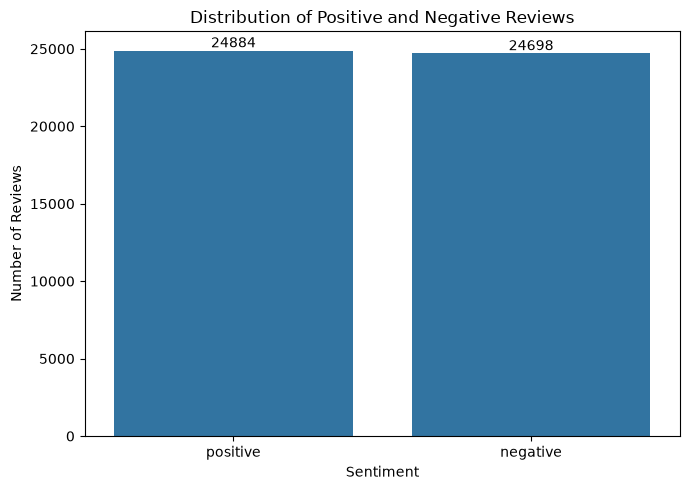

In [2]:

sentiment_counts = df["sentiment"].value_counts().reindex(
    ["positive", "negative"]
)

plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

ax.bar_label(ax.containers[0], fmt="%d")
plt.title("Distribution of Positive and Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


## 2. Review Length Distribution by Sentiment

This section compares the length of positive and negative movie reviews to identify differences in their distributions.


In [4]:

# Calculate review length using the number of words
df["review_length"] = df["cleaned_review"].str.split().str.len()

df.groupby("sentiment")["review_length"].describe()


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,24698.0,227.239048,163.334056,4.0,127.0,173.0,275.75,1491.0
positive,24884.0,230.860955,175.940652,10.0,124.0,171.0,281.00,2459.0


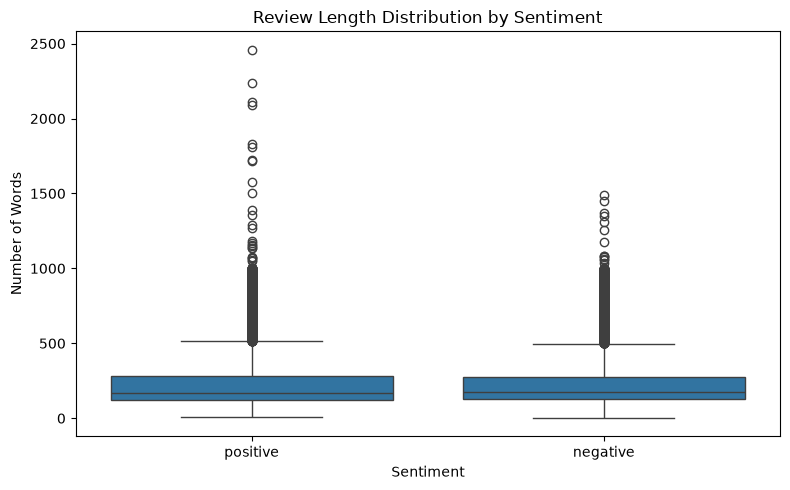

In [5]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="sentiment",
    y="review_length"
)

plt.title("Review Length Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show()
